# Lecture 4: Quantitative Validity of the Real Business Cycle Model

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/johanneswieland/RBC/blob/main/lectures/04_quantitative_validity.ipynb)

**Economics 210A: Macroeconomics** · Johannes Wieland

We are now ready to assess the empirical success of the model we developed in Lectures 2 and 3. We evaluate it along several dimensions. Specifically, we look at the following properties of the data and check whether the model can reproduce them:

- volatility,
- correlations,
- amplification of shocks,
- propagation of shocks:
  - internal dynamics,
  - built-in persistence (serial correlation of the exogenous forcing variables).

We begin with the case for the model (Section 1) and then turn to its weaknesses. Ideally, we would like a model that does not rely heavily on the persistence and volatility of the exogenous forcing variables. Instead, we want a model that generates persistence and volatility **endogenously**.

## Readings

- Cooley, T. F. and E. C. Prescott (1995), "[Economic Growth and Business Cycles](https://doi.org/10.1515/9780691218052-005)," in T. F. Cooley (ed.), *Frontiers of Business Cycle Research*, Princeton University Press.
- King, R. G. and S. T. Rebelo (1999), "[Resuscitating Real Business Cycles](https://doi.org/10.1016/S1574-0048%2899%2910022-3)," *Handbook of Macroeconomics*, Vol. 1B, Ch. 14.
- Cogley, T. and J. M. Nason (1995), "[Output Dynamics in Real-Business-Cycle Models](https://ideas.repec.org/a/aea/aecrev/v85y1995i3p492-511.html)," *American Economic Review* 85(3).
- Rotemberg, J. J. and M. Woodford (1996), "[Real-Business-Cycle Models and the Forecastable Movements in Output, Hours, and Consumption](https://ideas.repec.org/a/aea/aecrev/v86y1996i1p71-89.html)," *American Economic Review* 86(1).

## Setup

The model code is in [`code/rbc_ct.py`](../code/rbc_ct.py). This lecture adds stochastic shocks and simulation (`rbc.shock_process`, `rbc.state_space`, `rbc.simulate`). The data come from [`code/bcdata.py`](../code/bcdata.py), as in Lecture 1.

In [1]:
import sys, os
if "google.colab" in sys.modules and not os.path.exists("RBC"):
    !git clone -q https://github.com/johanneswieland/RBC.git
    os.chdir("RBC/lectures")
sys.path.insert(0, os.path.abspath("../code"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rbc_ct as rbc
import bcdata
from bcdata import COLORS, set_plot_style

set_plot_style()
pd.set_option("display.precision", 2)

p = rbc.Params(sg=0.2)          # calibration of Lecture 3: Lecture 2 parameters plus G/Y = 0.2

## 1. The quantitative success of the RBC model

[King and Rebelo (1999)](https://doi.org/10.1016/S1574-0048%2899%2910022-3) make the case that the basic RBC model, despite its simplicity, accounts for a large part of postwar U.S. business cycles. Their method, **calibration**, has two steps:

1. Choose "reasonable" parameters and solve the model on a computer.
   - Target steady-state moments such as the long-run real interest rate, the fraction of time spent working, and the labor share.
   - Choose the other parameters from micro evidence or convention: an intertemporal elasticity of substitution of one, a labor supply elasticity of one, depreciation of about 10% per year.
   - Fit the technology process to the time-series properties of the Solow residual.
2. See how well the model matches the business cycle facts of Lecture 1: standard deviations, autocorrelations, and correlations with output.

We did the first step in Lectures 2 and 3: log utility in consumption, a Frisch elasticity $\eta = 1$, $\alpha = 1/3$, $\rho = 0.04$ and $\delta = 0.08$ per year, $\bar G/\bar Y = 0.2$, and technology with quarterly persistence 0.95. For the second step King and Rebelo use a vivid exercise: with the policy functions solved from theory, they feed the *actual* Solow residual into the model and compare the simulated series with the data, quarter by quarter. We do the same with our model and our calibration.

The data are those of Lecture 1, including the COVID-19 recession.

In [2]:
END = None                  # latest data, including COVID-19; try "2019-12-31" (pre-COVID)
raw = bcdata.load_raw()
levels = bcdata.build_series(raw.loc[:END])
# log real government spending (consumption + gross investment) per capita, used in Section 4
levels["Government"] = np.log(raw["G_real"] * 1e9 / (raw["population"] * 1e3)).loc[levels.index]
cycles, _ = bcdata.hp_cycles(levels)
data = bcdata.bc_moments(cycles)
T = len(levels)
print(f"{T} quarters, {levels.index[0]:%Y}Q{levels.index[0].quarter} to {levels.index[-1]:%Y}Q{levels.index[-1].quarter}")

Downloaded data: 1947-01-01 to 2026-07-01
318 quarters, 1947Q2 to 2026Q3


**Technology.** We measure $\hat z_t$ by the Solow residual of Lecture 1 relative to a linear trend. (The trend is balanced growth, which our model abstracts from. The HP filter removes any linear trend, so the HP-filtered $\hat z_t$ is exactly the HP-filtered Solow residual.)

**Expectations.** Households expect technology to return to trend at rate $\theta$, with quarterly persistence $e^{-\theta/4} = 0.95$ as in Lecture 2. Each quarter they observe a new value of the Solow residual, revise their expectations, and re-optimize. Their decisions are therefore given by the policy function (POL) of Lecture 2, $\hat\lambda_t = \nu_{\lambda k}\hat k_t + \nu_{\lambda z}\hat z_t$, evaluated at the current capital stock and the current Solow residual.

**Capital.** Capital is the only state variable that is not taken from the data. It starts at its steady state and accumulates according to (POL), $\dot{\hat k}_t = \mu_s\hat k_t + \nu_{kz}\hat z_t$. If $\hat z_t = \hat z_n$ is constant during quarter $n$, which lasts $h = 1/4$ year, the solution of this differential equation over the quarter is

$$
\begin{aligned}
\hat k_{n+h} &= e^{\mu_s h}\hat k_n + \int_0^h e^{\mu_s (h-u)}\,du\;\nu_{kz}\hat z_n \\
&= e^{\mu_s h}\hat k_n + \frac{e^{\mu_s h} - 1}{\mu_s}\,\nu_{kz}\hat z_n .
\end{aligned}
\tag{HIST}
$$

Given $(\hat k_t, \hat\lambda_t, \hat z_t)$ we recover all other variables as in Lecture 2. We HP-filter the model series exactly like the data and compute the same moments. There is no free parameter: the size of the shocks is the size of the measured Solow residual. The last column correlates the HP-filtered model series with its counterpart in the data, quarter by quarter.

In [3]:
# model variable -> name of the data series
NAMES = {"Y": "GDP", "C": "Consumption", "I": "Investment", "L": "Hours", "W": "Real Wage",
         "K": "Capital", "r (p.p.)": "Real Rate", "Z": "TFP"}
ROWS = ["GDP", "Consumption", "Investment", "Hours", "GDP per Hour", "Real Wage", "Capital", "Real Rate", "TFP"]


def hp_cycle_matrix(T, lam=1600):
    # the HP cycle is y - tau with tau = (I + lam D'D)^{-1} y (Lecture 1), a linear map of y
    D = np.diff(np.eye(T), 2, axis=0)
    return np.eye(T) - np.linalg.inv(np.eye(T) + lam * D.T @ D)


HPC = hp_cycle_matrix(T)

theta = -4 * np.log(0.95)                     # quarterly persistence 0.95, as in Lecture 2
pc = rbc.policy_coefficients(p, theta)        # coefficients of (POL)

# technology: the Solow residual relative to a linear trend
tfp = levels["TFP"].values
q = np.arange(T)
z = tfp - np.polyval(np.polyfit(q, tfp, 1), q)

# capital: start at the steady state and integrate (POL) quarter by quarter, (HIST)
h = 0.25                                      # one quarter, in years
e = np.exp(pc["mu_s"] * h)
k = np.zeros(T)
for n in range(T - 1):
    k[n + 1] = e * k[n] + pc["nu_kz"] * (e - 1) / pc["mu_s"] * z[n]
lam = pc["nu_lk"] * k + pc["nu_lz"] * z       # (POL)

hist = rbc.derived(p, levels.index, k, lam, z, np.zeros(T))
x = hist.rename(columns=NAMES)[list(NAMES.values())]
x["GDP per Hour"] = x["GDP"] - x["Hours"]
fed = pd.DataFrame(HPC @ x.values, index=levels.index, columns=x.columns)   # HP cycles, in %

kr = pd.concat({"Data": data.loc[ROWS], "Model: measured Solow residual": bcdata.bc_moments(fed).loc[ROWS]}, axis=1)
kr[("", "Corr(model, data)")] = fed[ROWS].corrwith(cycles[ROWS])
kr

Data                                             \
             SD (%) SD / SD(GDP) Corr(x, GDP) Corr(x_t, x_t-1)   
GDP            2.07         1.00         1.00             0.80   
Consumption    1.06         0.51         0.76             0.68   
Investment     6.30         3.05         0.88             0.80   
Hours          2.01         0.97         0.86             0.81   
GDP per Hour   1.07         0.51         0.32             0.75   
Real Wage      1.16         0.56         0.02             0.73   
Capital        0.54         0.26        -0.12             0.96   
Real Rate      1.77         0.85        -0.02             0.50   
TFP            1.22         0.59         0.79             0.78   

             Model: measured Solow residual                            \
                                     SD (%) SD / SD(GDP) Corr(x, GDP)   
GDP                                    1.57         1.00         1.00   
Consumption                            0.60         0.38         0.89   
Investment                             5.70         3.64         0.99   
Hours                                  0.53         0.34         0.97   
GDP per Hour                           1.06         0.68         0.99   
Real Wage                              1.06         0.68         0.99   
Capital                                0.45         0.29         0.03   
Real Rate                              0.19         0.12         0.96   
TFP                                    1.22         0.78         1.00   

                                                 
             Corr(x_t, x_t-1) Corr(model, data)  
GDP                      0.78              0.81  
Consumption              0.83              0.58  
Investment               0.77              0.77  
Hours                    0.78              0.28  
GDP per Hour             0.79              0.75  
Real Wage                0.79              0.33  
Capital                  0.96              0.39  
Real Rate                0.78             -0.12  
TFP                      0.78              1.00

The real rate is in percentage points, all other variables are in percent. The TFP row is the same in the model and the data by construction. Fed with nothing but the measured Solow residual, our model reproduces a lot:

1. It generates about three quarters of the volatility of output (1.6% vs. 2.1%).
2. It gets the ranking of volatilities right: investment is more than three times as volatile as output, and consumption is much less volatile than output (0.38 times as volatile, 0.51 in the data).
3. Output, consumption, and investment are nearly as persistent as in the data, and they are procyclical.
4. The model series track the data quarter by quarter: the correlation between model and data output is 0.81, for investment 0.77, and for consumption 0.58.

The weak spot is the labor market. Hours in the model are only about a quarter as volatile as in the data, and the correlation between model and data hours is only about 0.3. The real wage is much too procyclical, and the real interest rate barely moves. The figure plots the HP-filtered series, as in King and Rebelo's figures; grey bars are NBER recessions.

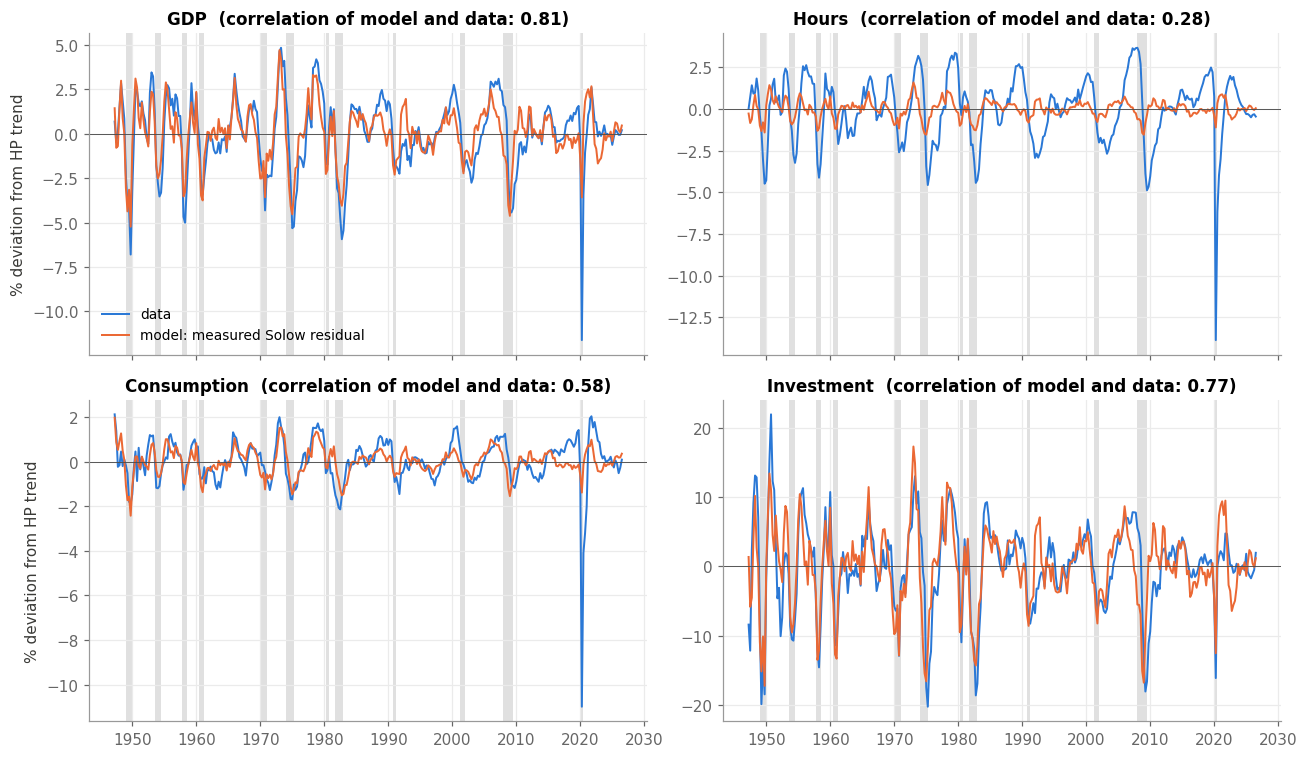

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for ax, var in zip(axes.flat, ["GDP", "Hours", "Consumption", "Investment"]):
    bcdata.shade_recessions(ax, levels["recession"])
    ax.plot(cycles.index, cycles[var], color=COLORS["gdp"], lw=1.3, label="data")
    ax.plot(fed.index, fed[var], color=COLORS["series"], lw=1.3, label="model: measured Solow residual")
    ax.axhline(0, color="0.3", lw=0.6)
    ax.set_title(f"{var}  (correlation of model and data: {kr.loc[var, ('', 'Corr(model, data)')]:.2f})")
for ax in axes[:, 0]:
    ax.set_ylabel("% deviation from HP trend")
axes[0, 0].legend(loc="lower left", fontsize=9)
plt.tight_layout()

The model reproduces the timing and depth of most postwar recessions in output, consumption, and investment, because the Solow residual falls in almost every recession (Lecture 1). Hours are a different story. In the model hours move with the Solow residual and have small amplitude. In the data hours fall by much more in recessions, and they keep falling after the recessions of 1990–91, 2001, and 2007–09 ("jobless recoveries"), while the Solow residual, and with it hours in the model, recovers quickly.

The big exception is the COVID-19 recession. In 2020Q2 output fell almost 12% below trend, but the Solow residual fell by less than 3%, so output in the model falls by less than 4%. Afterwards the Solow residual is above trend, and the model predicts a boom in 2020–21 while hours in the data recover slowly.

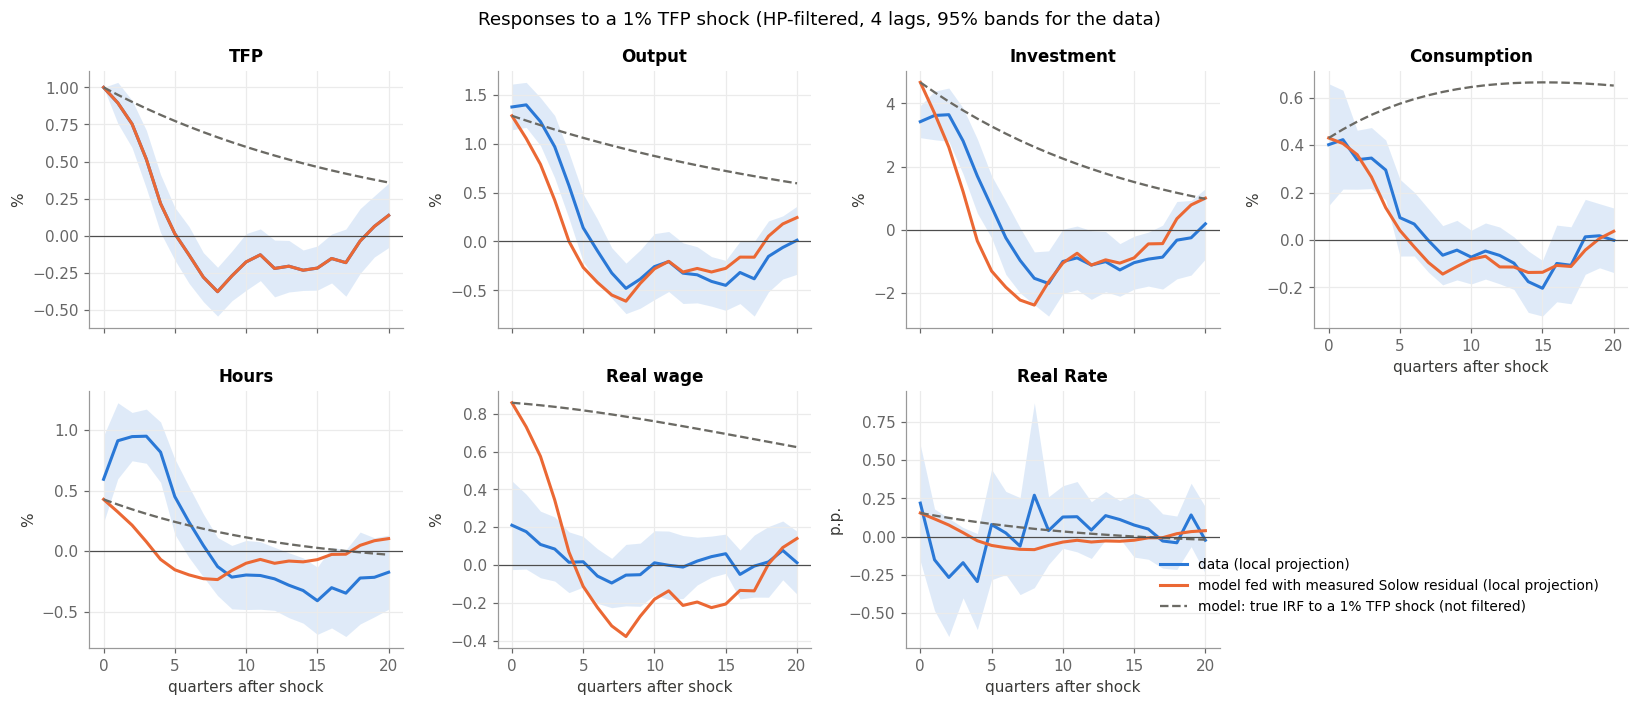

In [5]:
# conditional IRFs: local projections on the HP-filtered Solow residual, as in Lecture 1 (Section 5)
import statsmodels.api as sm
from scipy.stats import norm

H_LP, LAGS_LP, CONF = 20, 4, 0.95
lp_vars = ["TFP", "GDP", "Investment", "Consumption", "Hours", "Real Wage", "Real Rate"]


def local_projection(y, shock, H=20, lags=4, conf=0.95):
    # IRF of y to shock: for each h, regress y_{t+h} on shock_t, `lags` lags of shock and of y (Lecture 1)
    same = y.equals(shock)
    X = pd.concat({"shock": shock,
                   **{f"shock_l{j}": shock.shift(j) for j in range(1, lags + 1)},
                   **({} if same else {f"y_l{j}": y.shift(j) for j in range(1, lags + 1)})}, axis=1)
    X = sm.add_constant(X)
    zc = norm.ppf(0.5 + conf / 2)
    rows = []
    for hh in range(H + 1):
        d = pd.concat([y.shift(-hh).rename("lhs"), X], axis=1).dropna()
        res = sm.OLS(d["lhs"], d.drop(columns="lhs")).fit(cov_type="HAC", cov_kwds={"maxlags": hh + 1})
        b, se = res.params["shock"], res.bse["shock"]
        rows.append({"h": hh, "irf": b, "lo": b - zc * se, "hi": b + zc * se})
    return pd.DataFrame(rows).set_index("h")


lp_data = {v: local_projection(cycles[v], cycles["TFP"], H_LP, LAGS_LP, CONF) for v in lp_vars}
lp_model = {v: local_projection(fed[v], fed["TFP"], H_LP, LAGS_LP, CONF) for v in lp_vars}
true_irf = rbc.irf(p, z0=0.01, theta_z=theta, T=H_LP / 4, n=H_LP + 1).rename(columns=NAMES)   # 1% TFP shock

titles = {"GDP": "Output", "Real Wage": "Real wage"}
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5), sharex=True)
hq = np.arange(H_LP + 1)
for ax, v in zip(axes.flat, lp_vars):
    r = lp_data[v]
    ax.fill_between(hq, r["lo"], r["hi"], color=COLORS["gdp"], alpha=0.15, lw=0)
    ax.plot(hq, r["irf"], color=COLORS["gdp"], lw=2, label="data (local projection)")
    ax.plot(hq, lp_model[v]["irf"], color=COLORS["series"], lw=2,
            label="model fed with measured Solow residual (local projection)")
    ax.plot(hq, true_irf[v].values, color=COLORS["trend"], lw=1.5, ls="--",
            label="model: true IRF to a 1% TFP shock (not filtered)")
    ax.axhline(0, color="0.3", lw=0.8)
    ax.set_title(titles.get(v, v))
    ax.set_ylabel("p.p." if v == "Real Rate" else "%")
axes[1, 3].remove()
axes[0, 3].tick_params(labelbottom=True)
for ax in [*axes[1, :3], axes[0, 3]]:
    ax.set_xlabel("quarters after shock")
h_, l_ = axes[0, 0].get_legend_handles_labels()
fig.legend(h_, l_, loc="lower right", bbox_to_anchor=(0.98, 0.12), fontsize=9)
fig.suptitle(f"Responses to a 1% TFP shock (HP-filtered, {LAGS_LP} lags, {int(CONF * 100)}% bands for the data)")
plt.tight_layout()

### 1.1 What is attractive about the RBC model?

While the model has a number of limitations, it also has a number of desirable properties:

1. It studies business cycles in general equilibrium, so we take into account the equilibrium responses of all variables to technology shocks.
2. It is a Walrasian economy with no frictions in which all markets clear. We do not need ad hoc assumptions about how and why markets fail to clear.
3. It is very parsimonious: it has only a handful of parameters. The model is hugely over-identified, so we could use over-identification tests to check its validity.
4. We can use the same model to explain growth and fluctuations around the growth trend.
5. It explains macro facts from micro-foundations in which all agents optimize. We can therefore study changes in policy without being subject to the [Lucas critique](https://en.wikipedia.org/wiki/Lucas_critique).

In summary, with one model we can address many questions, and at the same time we put enormous discipline on the model. An important point about RBC models is that fluctuations are fully optimal, so there is no need for stabilization policy. In other words, recessions are not bad in the sense that they do not reflect disruptions to how markets operate. Taken literally, the enormous unemployment during the Great Depression was a great vacation, since the unemployed **optimally** chose not to work and to enjoy leisure!

This is the quantitative success that made the RBC model the starting point of modern business cycle research. In the rest of the lecture we ask how much of this success is due to the model and how much is built into the measured shocks (see also exercise 1).

## 2. Amplification and propagation

Mechanisms that increase endogenous volatility are often called **amplification mechanisms**. To get a sense of endogenous amplification, consider a simple model with inelastic labor supply, $L_t = 1$, in which households save a constant fraction $s$ of output (as in the Solow growth model):

$$
\dot K_t = s Y_t - \delta K_t, \qquad Y_t = Z_t K_t^{\alpha} . \tag{SOLOW}
$$

In the steady state $s\bar Y = \delta \bar K$. To log-linearize, divide (SOLOW) by $K_t$ and linearize around the steady state:

$$
\begin{aligned}
\frac{\dot K_t}{K_t} &= s\frac{Y_t}{K_t} - \delta \\
\dot{\hat k}_t &= s\frac{\bar Y}{\bar K}\left(\hat y_t - \hat k_t\right) \\
&= \delta\left(\hat y_t - \hat k_t\right) \\
&= \delta\left(\hat z_t + \alpha\hat k_t - \hat k_t\right) \\
&= \delta\hat z_t - (1-\alpha)\delta\,\hat k_t .
\end{aligned}
$$

Suppose technology increases permanently by $\Delta$ at $t_0 = 0$. The immediate effect on output is $\Delta$: capital is fixed in the short run, so $\hat y_0 = \hat z_0 = \Delta$. A one percent increase in $Z_t$ raises output $Y_t$ by one percent. This change in output is determined exogenously.

Over time more capital is accumulated. In the long run $\dot{\hat k}_t = 0$, so $\hat k_\infty = \Delta/(1-\alpha)$ and

$$
\begin{aligned}
\hat y_\infty &= \Delta + \alpha\hat k_\infty \\
&= \Delta + \frac{\alpha}{1-\alpha}\Delta \\
&= \frac{1}{1-\alpha}\Delta .
\end{aligned}
$$

In other words, a 1% increase in technology raises output by $\frac{1}{1-\alpha}$%. Here, capital accumulation is the amplification mechanism, which gives output an extra kick beyond the immediate effect. We call $\frac{1}{1-\alpha} - 1 > 0$ the **endogenous amplification**.

Mechanisms that increase endogenous persistence are called **propagation mechanisms**. In the simple model capital accumulation is also a propagation mechanism, because the economy reaches its new steady state gradually: the capital gap $\hat k_t - \hat k_\infty$ closes at rate $(1-\alpha)\delta$, so

$$
\hat y_t = \Delta + \frac{\alpha}{1-\alpha}\Delta\left(1 - e^{-(1-\alpha)\delta t}\right).
$$

If a model relies too much on the properties of the exogenous variables, it is not very satisfactory, since we end up explaining the data with postulated exogenous variables. In summary, our desiderata in modeling business cycles are **strong amplification and strong propagation** inside the model.

How does the RBC model compare? The cell below plots the response of output to a permanent 1% increase in technology in the simple model and in the RBC model of Lectures 2 and 3.

,impact (%),long run (%),half-life of capital gap (years)
simple model,1.00,1.50,13.00
RBC model,1.06,1.28,4.55


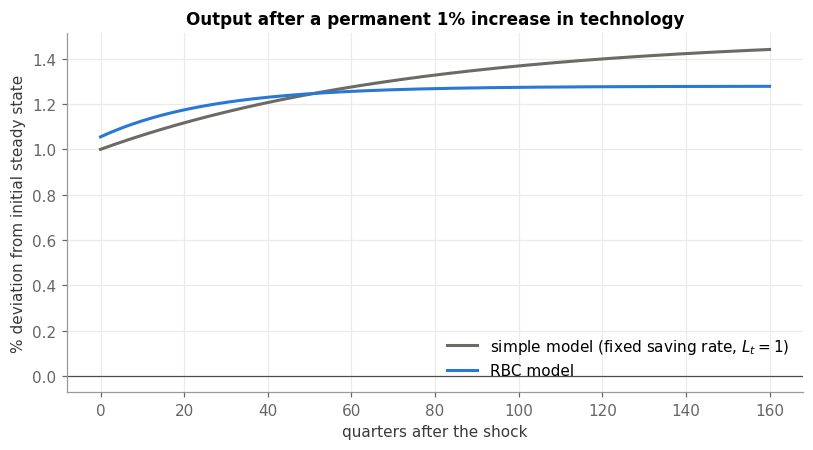

In [6]:
dz = 1.0                                   # permanent increase in technology, %
a, d = p.alpha, p.delta
t = np.linspace(0, 40, 801)                # years
y_simple = dz * (1 + a / (1 - a) * (1 - np.exp(-(1 - a) * d * t)))
y_rbc = rbc.irf_step(p, z0=dz / 100, T=40, n=801)["Y"]
mu_s = rbc.saddle(rbc.linear_system(p)[0])[0]   # stable eigenvalue: speed of convergence of the RBC model

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot(4 * t, y_simple, color=COLORS["trend"], lw=2, label="simple model (fixed saving rate, $L_t = 1$)")
ax.plot(4 * y_rbc.index, y_rbc, color=COLORS["gdp"], lw=2, label="RBC model")
ax.axhline(0, color="0.3", lw=0.8)
ax.set_xlabel("quarters after the shock")
ax.set_ylabel("% deviation from initial steady state")
ax.set_title("Output after a permanent 1% increase in technology")
ax.legend(loc="lower right")
plt.tight_layout()

y_long = rbc.irf_step(p, z0=dz / 100, T=400, n=401)["Y"].iloc[-1]
pd.DataFrame({
    "impact (%)": [y_simple[0], y_rbc.iloc[0]],
    "long run (%)": [dz / (1 - a), y_long],
    "half-life of capital gap (years)": [np.log(2) / ((1 - a) * d), np.log(2) / -mu_s],
}, index=["simple model", "RBC model"])

The RBC model adds a second amplification mechanism on impact: labor supply. Hours rise because the marginal product of labor rises, so output increases by more than the change in technology. In the long run the two models give similar answers. Hours end slightly below their initial level because $\bar G$ is fixed in levels (Lecture 3), so long-run output rises by a bit less than $\frac{1}{1-\alpha}$%. The RBC model converges much *faster* than the simple model, because the saving rate is not fixed: the household saves a lot while the return to capital is high. Capital accumulation in the RBC model therefore propagates shocks only weakly. We return to this point in Section 5.

## 3. The canonical real business cycle model

[Cooley and Prescott (1995)](https://doi.org/10.1515/9780691218052-005) develop and calibrate a standard ("bare-bones") model of the business cycle literature. They focus on technology shocks as the only driving force of business cycles. This class of models is often called **real business cycle** (RBC) models, to emphasize that the shocks are real (e.g., technology shocks) and not nominal (e.g., monetary shocks). Their model is similar to the one we developed and analyzed, and their calibration is similar to ours.

The moments of the data (variances and correlations) are computed after removing the trend component of the macroeconomic series with the HP filter (Lecture 1). For the model, we simulate the calibrated model, HP-filter the simulated series, compute the moments of the filtered series, and compare them with the moments in the data. The table reproduces their results.

| Variable | Data st.dev. | Model st.dev. |
|---|---|---|
| Output | 1.72 | 1.35 |
| Consumption | total: 1.27; nondurables: 0.86 | 0.329 |
| Investment | total: 8.24; fixed: 5.34 | 5.95 |
| Hours | 1.59 | 0.769 |
| Employment | 1.14 | |
| Serial correlation of output, $\rho(Y_t, Y_{t-1})$ | 0.85 | 0.698 |
| $\rho(Y_t, C_t)$ | 0.83 | 0.84 |
| $\rho(Y_t, I_t)$ | 0.91 | 0.992 |
| $\rho(Y_t, L_t)$ | hours: 0.86; employment: 0.85 | 0.986 |
| $\rho(Y_t, Z_t)$ | 0.77 (Solow residual) | 0.98 |
| $\rho(Y_t, W_t)$ | hourly rate: 0.68; compensation per hour: 0.03 | 0.978 |

Broadly, the match is not perfect, but it is not terrible either. Some prominent facts about the business cycle are reproduced by the model, for instance $\sigma_I > \sigma_Y > \sigma_C$. This finding may be somewhat surprising given how simple the model is, and it is why the literature does not use a formal metric such as a test of over-identifying restrictions to reject the model. The objective is to check whether the model can "roughly" reproduce the salient features of business cycles.

### 3.1 Simulating our model

We now do the same exercise with our model and compare it with the business cycle facts of Lecture 1.

**Stochastic technology.** In Lectures 2 and 3 technology followed deterministic paths. To simulate business cycles, we add random disturbances to the technology process (TFP) of Lecture 2:

$$
d\hat z_t = -\theta\,\hat z_t\,dt + \sigma_z\, d\mathcal{B}_t , \tag{OU}
$$

where $\mathcal{B}_t$ is a standard Brownian motion: its increments over an interval of length $h$ are independent and normally distributed with mean zero and variance $h$. (OU) is the Ornstein–Uhlenbeck process, the continuous-time analogue of an AR(1) process. Sampled at quarterly intervals ($h = 1/4$ year) it is exactly an AR(1) process:

$$
\begin{aligned}
\hat z_{t+h} &= e^{-\theta h}\hat z_t + \varepsilon_{t+h} , \\
\operatorname{Var}(\varepsilon_{t+h}) &= \sigma_z^2\,\frac{1 - e^{-2\theta h}}{2\theta} ,
\end{aligned}
$$

with quarterly persistence $\rho_z = e^{-\theta/4} = 0.95$ for our value of $\theta$.

**Solution.** In the linearized model the policy function of Lecture 2, (POL), still applies: $\hat\lambda_t = \nu_{\lambda k}\hat k_t + \nu_{\lambda z}\hat z_t$ with the same coefficients. The method of undetermined coefficients only used the expected change in technology, $\mathbb{E}_t[d\hat z_t] = -\theta\hat z_t\,dt$, and the Brownian increment has mean zero (certainty equivalence). Capital and technology then form a linear system,

$$
d\begin{bmatrix}\hat k_t \\ \hat z_t\end{bmatrix}
= \underbrace{\begin{bmatrix}\mu_s & \nu_{kz} \\ 0 & -\theta\end{bmatrix}}_{F}
\begin{bmatrix}\hat k_t \\ \hat z_t\end{bmatrix} dt
+ \begin{bmatrix}0 \\ \sigma_z\end{bmatrix} d\mathcal{B}_t , \tag{STATE}
$$

and every other variable is a linear function of $(\hat k_t, \hat z_t)$. Sampled at interval $h$, the state $X_t = (\hat k_t, \hat z_t)'$ follows a vector autoregression,

$$
X_{t+h} = e^{Fh} X_t + \epsilon_{t+h}, \qquad \operatorname{Var}(\epsilon_{t+h}) = \int_0^h e^{Fu}\begin{bmatrix}0 & 0 \\ 0 & \sigma_z^2\end{bmatrix} e^{F'u}\,du , \tag{DISC}
$$

which `rbc.simulate` uses to generate quarterly data without any approximation error. (`rbc.state_space` does the same for more general shock processes, which we use below.)

**Simulation.** We simulate 200 samples with as many quarters as the data, HP-filter each simulated series with $\lambda = 1600$, compute the moments of each sample, and average them across samples. We use the sample of Section 1. The model is linear, so all standard deviations are proportional to $\sigma_z$. We choose $\sigma_z$ so that the standard deviation of HP-filtered TFP in the model equals that of the Solow residual in the data. All other moments are then predictions of the model.

In [7]:
def model_cycles(p, proc, sigma, n_sim=200, seed=0):
    # simulate n_sim samples of length T and return their HP cycles (in %, as in the data)
    out = []
    for df in rbc.simulate(p, proc, sigma, T, n_sim=n_sim, seed=seed):
        x = df.rename(columns=NAMES)[list(NAMES.values())]
        x["GDP per Hour"] = x["GDP"] - x["Hours"]
        x["Government"] = df["G/Y"] / p.sg      # g = dG/Y, so log G deviates by g / (G/Y)
        out.append(pd.DataFrame(HPC @ x.values, columns=x.columns))
    return out


def model_moments(p, proc, sigma, n_sim=200, seed=0):
    sims = model_cycles(p, proc, sigma, n_sim, seed)
    with np.errstate(invalid="ignore"):       # a series without shocks (e.g. G) has no correlation
        return sum(bcdata.bc_moments(c) for c in sims) / len(sims)


theta = -4 * np.log(0.95)                     # quarterly persistence 0.95, as in Lecture 2
tech = rbc.shock_process(theta_z=theta)
unit = model_moments(p, tech, [1.0], n_sim=50)
sigma_z = data.loc["TFP", "SD (%)"] / unit.loc["TFP", "SD (%)"]
print(f"sigma_z = {sigma_z:.4f}: quarterly AR(1) with persistence {np.exp(-theta / 4):.2f} and "
      f"innovation s.d. {sigma_z * np.sqrt((1 - np.exp(-theta / 2)) / (2 * theta)):.4f}")

model = model_moments(p, tech, [sigma_z])
pd.concat({"Data": data.loc[ROWS], "Model: technology shocks": model.loc[ROWS]}, axis=1)

sigma_z = 0.0194: quarterly AR(1) with persistence 0.95 and innovation s.d. 0.0095


Data                                             \
             SD (%) SD / SD(GDP) Corr(x, GDP) Corr(x_t, x_t-1)   
GDP            2.07         1.00         1.00             0.80   
Consumption    1.06         0.51         0.76             0.68   
Investment     6.30         3.05         0.88             0.80   
Hours          2.01         0.97         0.86             0.81   
GDP per Hour   1.07         0.51         0.32             0.75   
Real Wage      1.16         0.56         0.02             0.73   
Capital        0.54         0.26        -0.12             0.96   
Real Rate      1.77         0.85        -0.02             0.50   
TFP            1.22         0.59         0.79             0.78   

             Model: technology shocks                            \
                               SD (%) SD / SD(GDP) Corr(x, GDP)   
GDP                              1.58         1.00         1.00   
Consumption                      0.61         0.39         0.93   
Investment                       5.67         3.58         0.99   
Hours                            0.52         0.33         0.98   
GDP per Hour                     1.08         0.68         0.99   
Real Wage                        1.08         0.68         0.99   
Capital                          0.39         0.25         0.17   
Real Rate                        0.19         0.12         0.97   
TFP                              1.22         0.77         1.00   

                               
             Corr(x_t, x_t-1)  
GDP                      0.71  
Consumption              0.77  
Investment               0.70  
Hours                    0.70  
GDP per Hour             0.72  
Real Wage                0.72  
Capital                  0.96  
Real Rate                0.70  
TFP                      0.70

The real rate is in percentage points, all other variables are in percent. The results look much like those of Cooley and Prescott:

1. Overall the match is not terrible.
2. The level of volatility is fine: the model generates most of the volatility of output, and investment is about three to four times as volatile as output while consumption is less volatile than output.
3. The dynamic properties of the model are off: output is less persistent than in the data.
4. A lot of the variability is driven by the "exogenous" shocks (the forcing variable): technology is almost as volatile as output.
5. There is too much correlation with output and productivity: in the model almost every variable is nearly perfectly correlated with output, because one shock drives everything.

Some differences to keep in mind. Our consumption series excludes durables, but consumption in the model is still too smooth: its volatility relative to output is about 0.4, against 0.5 in the data. Hours are much too smooth: their volatility relative to output is about a third of that in the data. In the model the real wage equals the marginal product of labor, $W_t = (1-\alpha)Y_t/L_t$, so the wage and output per hour have identical moments; in the data the wage is much less procyclical than productivity. And the real interest rate in the model is far less volatile than in the data, and strongly procyclical.

## 4. Critique of the RBC model

### 4.1 The quantitative match

When we look at the simulated data, we see that the **quantitative** match is far from perfect. Consumption is too smooth (much more so in Cooley and Prescott's comparison), and wages are too procyclical.

To be fair, there is only one shock in the model. By introducing more shocks we can improve the fit. For example, if we introduce shocks to government spending $G$, we can reduce the procyclicality of wages. From Lecture 3:

- $Z\uparrow \;\Rightarrow\; Y\uparrow,\ W\uparrow$: wages are very procyclical.
- $G\uparrow \;\Rightarrow\; Y\uparrow,\ W\downarrow$: wages are countercyclical.

So with the right mix of shocks you can improve the fit (see, e.g., [Christiano and Eichenbaum, 1992](https://www.jstor.org/stable/2117314)). But there are limits to this approach. One can keep adding shocks, but that does not necessarily improve the fit. For instance:

- $Z\uparrow \;\Rightarrow\; Y\uparrow,\ C\uparrow$, which fits the data.
- $G\uparrow \;\Rightarrow\; Y\uparrow,\ C\downarrow$: consumption is countercyclical, which we do not observe in the data.

Thus if we emphasize shocks to $G$, the results for consumption deteriorate while the results for wages improve.

Let us check this in the model. We add a government spending process like (OU), $d\hat g_t = -\theta\,\hat g_t\,dt + \sigma_g\,d\mathcal{B}^g_t$, with the same persistence as technology and a Brownian motion $\mathcal{B}^g_t$ independent of the one driving technology. We choose $\sigma_g$ so that HP-filtered government spending in the model is as volatile as real government consumption and investment per capita in the data (FRED [`GCEC1`](https://fred.stlouisfed.org/series/GCEC1)).

In [8]:
# calibrate sigma_g to the volatility of HP-filtered log G
gov = rbc.shock_process(theta_g=theta)
sigma_g = data.loc["Government", "SD (%)"] / model_moments(p, gov, [1.0], n_sim=50).loc["Government", "SD (%)"]
print(f"sigma_g = {sigma_g:.4f}")

both = rbc.shock_process(theta_z=theta, theta_g=theta)
cols = ["SD / SD(GDP)", "Corr(x, GDP)"]
rows = ["GDP", "Consumption", "Hours", "Real Wage"]
pd.concat({"Data": data.loc[rows, cols],
           "Technology": model.loc[rows, cols],
           "Government": model_moments(p, gov, [sigma_g]).loc[rows, cols],
           "Both": model_moments(p, both, [sigma_z, sigma_g]).loc[rows, cols]}, axis=1)

sigma_g = 0.0100


Data                Technology                Government  \
            SD / SD(GDP) Corr(x, GDP) SD / SD(GDP) Corr(x, GDP) SD / SD(GDP)   
GDP                 1.00         1.00         1.00         1.00         1.00   
Consumption         0.51         0.76         0.39         0.93         2.06   
Hours               0.97         0.86         0.33         0.98         1.52   
Real Wage           0.56         0.02         0.68         0.99         0.55   

                                 Both               
            Corr(x, GDP) SD / SD(GDP) Corr(x, GDP)  
GDP                 1.00         1.00         1.00  
Consumption        -0.98         0.45         0.72  
Hours               0.99         0.37         0.91  
Real Wage          -0.94         0.68         0.97

Conditional on government spending shocks alone, consumption and the real wage are countercyclical, as in Lecture 3. With both shocks at their calibrated volatilities, the correlation of the real wage with output barely falls, while the correlation of consumption with output already falls noticeably. Given the volatility of government spending in the data, $G$ shocks explain only a small share of the volatility of output.

How large would government spending shocks have to be? Because the two shocks are independent and the model is linear, the covariance matrix of the HP-filtered variables with both shocks is the sum of the covariance matrices under each shock alone, and the covariance matrix under $G$ shocks scales with $\sigma_g^2$. The figure varies $\sigma_g$ relative to its calibrated value.

corr(W, Y) matches the data at 9.8 x sigma_g: G shocks then account for 56% of the variance of output and corr(C, Y) = -0.63


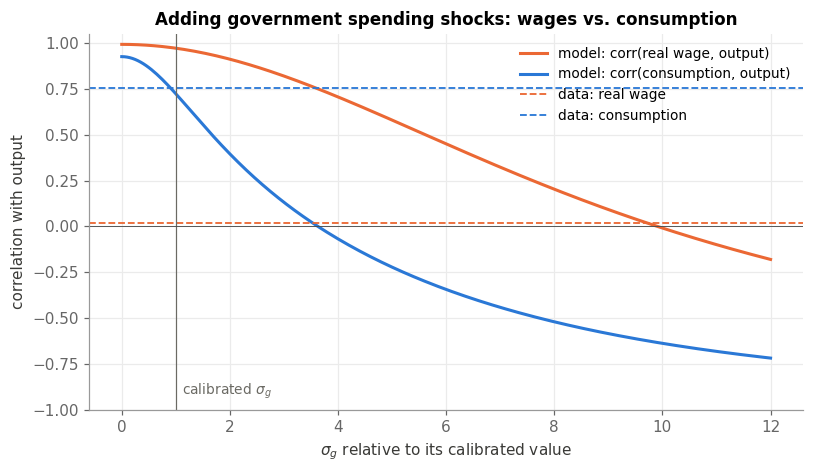

In [9]:
def cov_hp(proc, sigma, n_sim=200):
    # average covariance matrix of the HP-filtered variables across simulated samples
    sims = model_cycles(p, proc, sigma, n_sim)
    return sum(c.cov() for c in sims) / len(sims)

cov_z, cov_g = cov_hp(tech, [sigma_z]), cov_hp(gov, [sigma_g])
scale = np.linspace(0, 12, 241)


def corr_y(V, x):
    return V.loc[x, "GDP"] / np.sqrt(V.loc[x, x] * V.loc["GDP", "GDP"])

corr_w = [corr_y(cov_z + s**2 * cov_g, "Real Wage") for s in scale]
corr_c = [corr_y(cov_z + s**2 * cov_g, "Consumption") for s in scale]
share_g = [s**2 * cov_g.loc["GDP", "GDP"] / (cov_z + s**2 * cov_g).loc["GDP", "GDP"] for s in scale]

fig, ax = plt.subplots(figsize=(7.5, 4.4))
ax.plot(scale, corr_w, color=COLORS["series"], lw=2, label="model: corr(real wage, output)")
ax.plot(scale, corr_c, color=COLORS["gdp"], lw=2, label="model: corr(consumption, output)")
ax.axhline(data.loc["Real Wage", "Corr(x, GDP)"], color=COLORS["series"], ls="--", lw=1.2, label="data: real wage")
ax.axhline(data.loc["Consumption", "Corr(x, GDP)"], color=COLORS["gdp"], ls="--", lw=1.2, label="data: consumption")
ax.axvline(1, color=COLORS["trend"], lw=0.8)
ax.text(1.12, -0.92, "calibrated $\\sigma_g$", color=COLORS["trend"], fontsize=9)
ax.axhline(0, color="0.3", lw=0.6)
ax.set_xlabel("$\\sigma_g$ relative to its calibrated value")
ax.set_ylabel("correlation with output")
ax.set_ylim(-1, 1.05)
ax.set_title("Adding government spending shocks: wages vs. consumption")
ax.legend(loc="upper right", fontsize=9)
plt.tight_layout()

i = np.argmin(np.abs(np.array(corr_w) - data.loc["Real Wage", "Corr(x, GDP)"]))
print(f"corr(W, Y) matches the data at {scale[i]:.1f} x sigma_g: G shocks then account for "
      f"{100 * share_g[i]:.0f}% of the variance of output and corr(C, Y) = {corr_c[i]:.2f}")

To make wages as weakly procyclical as in the data, government spending shocks would have to be several times more volatile than in the data, and at that point consumption becomes countercyclical. We cannot fix both moments by mixing these two shocks.

### 4.2 Technology shocks can be controversial

**What is a "decline" in technology?** How is it possible to have technological regress? We measure technology with the Solow residual,

$$
\hat z_t = \hat y_t - (1-\alpha)\,\hat l_t - \alpha\,\hat k_t ,
$$

where $\alpha$ is estimated from the labor share, $1-\alpha = \frac{WL}{Y}$. Measured TFP fell a lot during the Great Depression in the U.S. But technological regress is unlikely to have caused the Depression. At least, we are not aware of any technological problem that led to the Great Depression. [Lucas (1994)](https://doi.org/10.1016/0304-3932%2894%2990055-8) writes (p. 13), after showing the Solow residuals for 1928–33:

> [I]magine trying to rewrite the Great Contraction chapter of *A Monetary History* with shocks of this kind playing the role Friedman and Schwartz assign to monetary contractions. What technological or psychological events could have induced such behavior in a large, diversified economy? How could such events have gone unremarked at the time, and remain invisible even to hindsight?

More generally, we cannot identify large movements in measured technology with particular events and discoveries. In Lecture 1 the Solow residual fell in almost every postwar recession.

**Is the Solow residual exogenous?** Another problem with using the Solow residual as a structural shock in RBC models is that $Z_t$ does not seem "exogenous." To identify the effects of a shock, we want it to be uncorrelated with other shocks. Otherwise, when we look at the response of the economy to a shock, we do not know whether we see the effect of a particular force ("technology") or the effect of something that is correlated with technology. We therefore usually require, for example, $\rho(Z, G) = 0$. There is no particular reason to believe that government spending raises the level of technology, at least in the short run. However, the Solow residual in the data is correlated with non-technology shocks:

- [Hall (1988)](https://doi.org/10.1086/261570): $\rho(Z, \text{demand shifters}) \neq 0$,
- [Evans (1992)](https://doi.org/10.1016/0304-3932%2892%2990012-Q): $\rho(Z, \text{monetary policy shocks}) \neq 0$.

This is a problem: if measured technology shocks are endogenous, the model can fit well even though technology has no causal effect on fluctuations. We could not conclude that technology drives business cycles.

**Only real shocks.** RBC models typically have only real shocks: technology, government spending, taxes, and preferences. However, nominal and monetary shocks can apparently be very important (e.g., [Friedman and Schwartz, 1963](https://www.nber.org/books-and-chapters/monetary-history-united-states-1867-1960)). Omitting them can lead to erroneous conclusions.

### 4.3 Are the parameters plausible?

There is a concern about the plausibility of the parameters the model needs. For RBC models to work, labor supply has to be elastic, and in particular the intertemporal elasticity of labor supply (the Frisch elasticity $\eta$) has to be high. The micro-level evidence suggests that these elasticities are fairly small. The cell below shows how the volatility of hours depends on $\eta$, holding the technology process fixed.

In [10]:
rows_eta = {}
for eta in [0.5, 1.0, 2.0, 4.0]:
    m = model_moments(rbc.Params(sg=0.2, eta=eta), tech, [sigma_z], n_sim=50)
    rows_eta[eta] = {"SD(GDP) (%)": m.loc["GDP", "SD (%)"],
                     "SD(Hours) / SD(GDP)": m.loc["Hours", "SD / SD(GDP)"],
                     "Corr(Real Wage, GDP)": m.loc["Real Wage", "Corr(x, GDP)"]}
tab = pd.DataFrame(rows_eta).T.rename_axis("Frisch elasticity")
tab.loc["data"] = [data.loc["GDP", "SD (%)"], data.loc["Hours", "SD / SD(GDP)"], data.loc["Real Wage", "Corr(x, GDP)"]]
tab

,SD(GDP) (%),SD(Hours) / SD(GDP),"Corr(Real Wage, GDP)"
Frisch elasticity,,,
0.5,1.43,0.21,1.00
1.0,1.57,0.33,0.99
2.0,1.76,0.45,0.98
4.0,1.96,0.56,0.97
data,2.07,0.97,0.02


A higher Frisch elasticity makes hours more volatile. But even an elasticity of 4, far above the micro estimates, falls well short of the relative volatility of hours in the data, and wages remain far too procyclical.

When we work with an aggregate model, the aggregate elasticity combines two things: (i) micro-level elasticities and (ii) aggregation. Aggregation can be very important. A striking example is due to [Houthakker (1955)](https://doi.org/10.2307/2296148): if every firm has a Leontief production function and the distribution of firms is Pareto, then the aggregate production function is Cobb–Douglas. Similarly, the distinction between the intensive and extensive margins of labor adjustment (Lecture 1) could be very important for the aggregate labor supply elasticity.

### 4.4 Weak propagation

RBC models lack strong propagation mechanisms ([Cogley and Nason, 1995](https://ideas.repec.org/a/aea/aecrev/v85y1995i3p492-511.html)). To match the persistence we see in the data, we have to rely on very persistent shocks. But if we have to put very persistent shocks into the model, what is the model's value in explaining the persistence of $Y$, $C$, and $I$? We get the conclusion by construction. Furthermore, [Rotemberg and Woodford (1996)](https://ideas.repec.org/a/aea/aecrev/v86y1996i1p71-89.html) find that the model fails to reproduce the predictable movements (and comovements) of variables that we observe in the data. In other words, the model relies excessively on the volatility of the exogenous shocks to match the volatility of the variables in the data. The next two sections discuss these papers.

## 5. Cogley and Nason (1995)

[Cogley and Nason (1995)](https://ideas.repec.org/a/aea/aecrev/v85y1995i3p492-511.html) note that output growth is serially correlated in the data: if output growth is high today, it is likely to be high in the next quarters as well. To document this fact they use a variety of techniques:

- the autocorrelation function (ACF): in the data, the autocorrelations at lags 1 and 2 are positive and significant;
- the spectrum and impulse responses (a series can be approximated by sine and cosine functions, and since these functions are periodic, we can look at the contribution of cycles of various lengths to the total variation).

Cogley and Nason then write down a basic RBC model and note that it has four broad mechanisms to propagate shocks:

1. **Built-in persistence of shocks**: $\hat z_t$ follows (OU), whose parameter $\theta$ governs persistence.
2. **Capital accumulation**: when technology is high, households save part of their output in the form of capital, and then enjoy higher output in the future by using this capital in production while investing less for some time.
3. **Intertemporal substitution**: households supply a lot of labor at the time of the shock and spread below-average labor supply over the following periods.
4. **Adjustment costs, gestation lags, etc.**: a shock today affects $K$, $L$ or other variables only a few periods later.

The model analyzed by Cogley and Nason has two shocks:

- technology $Z_t$: a random walk,
- government spending $G_t$: an AR(1) process.

They calibrate and simulate the model (a simple model without adjustment costs) and find essentially no serial correlation in output growth in the model. We repeat their exercise with our model: technology follows a random walk ($\theta = 0$ in (OU)) and government spending follows the process of Section 4. We compare the ACF of quarterly output growth in a very long simulated sample (the population ACF) with the ACF in the data.

In [11]:
def acf(x, lags=8):
    x = np.asarray(x) - np.mean(x)
    return np.array([x[k:] @ x[:len(x) - k] / (x @ x) for k in range(1, lags + 1)])

LAGS = 8
lags = np.arange(1, LAGS + 1)
dy_data = acf(levels["GDP"].diff().dropna(), LAGS)
dz_data = acf(levels["TFP"].diff().dropna(), LAGS)
band = 2 / np.sqrt(T)                          # approximate 95% band under no autocorrelation

N_LONG = 100_000                               # quarters
rw = rbc.shock_process(theta_z=0.0, theta_g=theta)
sim_rw = rbc.simulate(p, rw, [sigma_z, sigma_g], N_LONG, seed=3)
dy_rw, dz_rw = acf(np.diff(sim_rw["Y"]), LAGS), acf(np.diff(sim_rw["Z"]), LAGS)
pd.DataFrame({"data: output growth": dy_data, "model (random-walk TFP): output growth": dy_rw},
             index=pd.Index(lags, name="lag (quarters)")).T.round(2)

lag (quarters),1,2,3,4,5,6,7,8
data: output growth,0.18,0.07,-0.00,-0.09,-0.11,-0.1,-0.06,-0.03
model (random-walk TFP): output growth,0.01,0.00,0.01,0.00,0.01,0.0,-0.00,0.00


In the model, output growth is serially uncorrelated, because the growth rate of technology is serially uncorrelated and the model adds almost no propagation of its own.

Another metric they use is empirical impulse responses. They identify the shocks in the data with a structural VAR in output growth and hours, in the style of [Blanchard and Quah (1989)](https://www.jstor.org/stable/1827924):

$$
\begin{bmatrix}\Delta \ln Y_t \\ \ln L_t\end{bmatrix}
= \begin{bmatrix} a_{11}(\mathbb{L}) & a_{12}(\mathbb{L}) \\ a_{21}(\mathbb{L}) & a_{22}(\mathbb{L})\end{bmatrix}
\begin{bmatrix}\varepsilon^S_t \\ \varepsilon^D_t\end{bmatrix} ,
$$

where $\mathbb{L}$ is the lag operator, $\varepsilon^S_t$ is a supply shock (like $Z_t$), and $\varepsilon^D_t$ is a demand shock (like $G_t$). The identifying assumption is that only $\varepsilon^S_t$ has a permanent effect on $Y_t$. (Obviously one may ask what happens with a long-lasting demand shock, e.g., the Cold War.) In the data, output growth shows a hump-shaped response to a demand shock, which the model cannot generate.

**More persistent technology growth.** Cogley and Nason then suppose that the *growth rate* of technology is an AR(1) process (log TFP is ARIMA(1,1,0)). The continuous-time analogue is

$$
d\hat z_t = x_t\,dt, \qquad dx_t = -\theta_x x_t\,dt + \sigma_x\,d\mathcal{B}_t .
$$

With enough persistence in $x_t$, they can match the serial correlation of output growth. The cell below varies the persistence of TFP growth, $e^{-\theta_x/4}$ per quarter, and records the first autocorrelation of output growth and of TFP growth in the model. We then pick the value of $\theta_x$ that makes output growth most autocorrelated. (Our model is in continuous time and we sample it at the end of each quarter. The autocorrelations do not depend on $\sigma_x$, so we set it to $\sigma_z$.)

most autocorrelated output growth at theta_x = 2.05 (quarterly persistence of TFP growth 0.60): first autocorrelation 0.41 for output growth, 0.72 for TFP growth


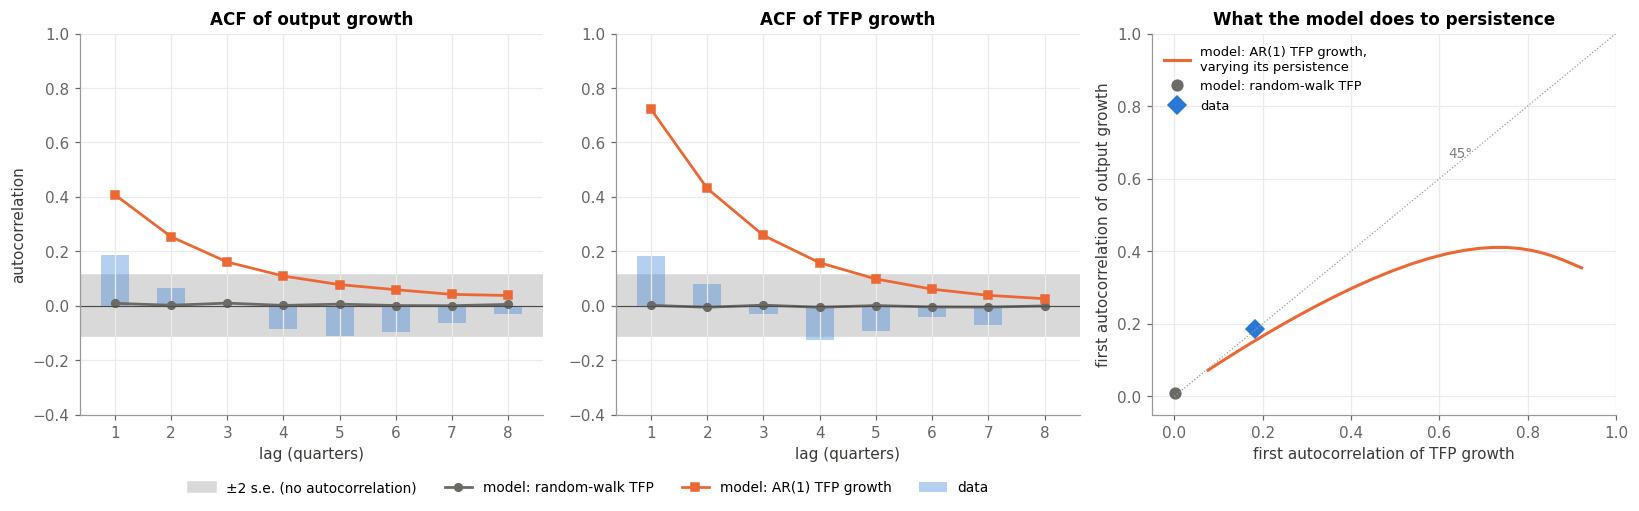

In [12]:
def acf_arima(theta_x, lags=LAGS, n=N_LONG):
    sim = rbc.simulate(p, rbc.shock_process(theta_dz=theta_x), [sigma_z], n, seed=4)
    return acf(np.diff(sim["Y"]), lags), acf(np.diff(sim["Z"]), lags)

grid = np.geomspace(0.5, 30, 30)                       # theta_x: quarterly persistence of TFP growth 0.88 to 0.0006
ac1 = np.array([[a[0] for a in acf_arima(th, 1, 50_000)] for th in grid])   # (output, TFP)
theta_x = grid[np.argmax(ac1[:, 0])]
dy_ar, dz_ar = acf_arima(theta_x)
print(f"most autocorrelated output growth at theta_x = {theta_x:.2f} (quarterly persistence of TFP "
      f"growth {np.exp(-theta_x / 4):.2f}): first autocorrelation {dy_ar[0]:.2f} for output growth, "
      f"{dz_ar[0]:.2f} for TFP growth")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), gridspec_kw={"width_ratios": [1, 1, 1]})
for ax, dat, m_rw, m_ar, title in [(axes[0], dy_data, dy_rw, dy_ar, "ACF of output growth"),
                                    (axes[1], dz_data, dz_rw, dz_ar, "ACF of TFP growth")]:
    ax.bar(lags, dat, width=0.5, color=COLORS["gdp"], alpha=0.35, label="data")
    ax.axhspan(-band, band, color="0.85", zorder=0, label="±2 s.e. (no autocorrelation)")
    ax.plot(lags, m_rw, "o-", color=COLORS["trend"], lw=1.8, ms=5, label="model: random-walk TFP")
    ax.plot(lags, m_ar, "s-", color=COLORS["series"], lw=1.8, ms=5, label="model: AR(1) TFP growth")
    ax.axhline(0, color="0.3", lw=0.8)
    ax.set_xticks(lags)
    ax.set_xlabel("lag (quarters)")
    ax.set_ylim(-0.4, 1.0)
    ax.set_title(title)
axes[0].set_ylabel("autocorrelation")

ax = axes[2]
ax.plot(ac1[:, 1], ac1[:, 0], color=COLORS["series"], lw=2, label="model: AR(1) TFP growth,\nvarying its persistence")
ax.plot([dz_rw[0]], [dy_rw[0]], "o", color=COLORS["trend"], ms=7, label="model: random-walk TFP")
ax.plot([dz_data[0]], [dy_data[0]], "D", color=COLORS["gdp"], ms=8, label="data")
ax.plot([0, 1], [0, 1], color="0.6", lw=0.8, ls=":")
ax.text(0.62, 0.66, "45°", color="0.5", fontsize=9)
ax.set_xlim(-0.05, 1)
ax.set_ylim(-0.05, 1)
ax.set_xlabel("first autocorrelation of TFP growth")
ax.set_ylabel("first autocorrelation of output growth")
ax.set_title("What the model does to persistence")
ax.legend(loc="upper left", fontsize=8.5)
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=4, fontsize=9, bbox_to_anchor=(0.36, -0.06))
plt.tight_layout()

The right panel summarizes the result. Every point of the model curve lies below the 45° line: the model turns autocorrelated TFP growth into *less* autocorrelated output growth. The reason is labor supply. A shock to TFP growth signals that technology will keep rising for some time. Households are richer immediately and work less, before technology has increased much: output falls on impact and rises afterwards, which makes output growth less persistent than TFP growth. Even at the best persistence, output growth is at most about as autocorrelated as in the data, and only if TFP growth is far more autocorrelated than the Solow residual in the data. The persistence of output growth is imported from the shocks, not generated by the model. This approach also fails on other dimensions: it implies too much serial correlation in TFP, and it fails to match the response of output growth to a transitory shock, where the model cannot generate the hump-shaped response observed in the data.

If you add capital adjustment costs,

$$
Y_t = Z_t K_t^{\alpha}L_t^{1-\alpha} - \frac{\alpha_K}{2}\left(\frac{\dot K_t}{K_t}\right)^2 ,
$$

or gestation lags (investment today becomes productive capital only after some time), the response of output growth is still not satisfying: one can get some persistence in output growth, but not a hump-shaped response. Models with labor adjustment costs have similar problems.

The bottom line of Cogley and Nason is that you need to build a lot of persistence into the shocks, because the model cannot generate very persistent responses to serially uncorrelated shocks.

## 6. Rotemberg and Woodford (1996)

[Rotemberg and Woodford (1996)](https://ideas.repec.org/a/aea/aecrev/v86y1996i1p71-89.html) have a simple but powerful idea: in the data, shocks lead to large **predictable** movements and **co**movements in the series. In the basic RBC model, predictable movements are small. Furthermore, predictable comovements can even have the wrong sign.

To identify the shocks, they estimate a VAR in output growth $\Delta y_t$, the consumption–output ratio $c_t - y_t$, and hours $h_t$ (lowercase letters are logs):

$$
u_t = \begin{bmatrix}\Delta y_t \\ c_t - y_t \\ h_t\end{bmatrix}, \qquad u_t = A u_{t-1} + \varepsilon_t . \tag{VAR}
$$

All variables in this system are stationary. We want to know the predictable movements in the variables. To construct them, Rotemberg and Woodford use impulse response functions (IRFs), the path of a variable in response to a shock. In the VAR, the response of output growth at horizons $0, 1, 2, \dots, k$ is

$$
e_1\varepsilon_t,\quad e_1 A\varepsilon_t,\quad e_1 A^2\varepsilon_t,\quad \dots,\quad e_1 A^k\varepsilon_t ,
$$

where $e_1 = [1\ 0\ 0]$ is a selection vector. This is the response of the first difference of output. The cumulative response of output growth gives the response of the *level* of output (hats now denote predictable movements):

$$
\begin{aligned}
\Delta\hat y_t + \Delta\hat y_{t+1} + \dots + \Delta\hat y_{t+k}
&= (\hat y_t - \hat y_{t-1}) + (\hat y_{t+1} - \hat y_t) + \dots + (\hat y_{t+k} - \hat y_{t+k-1}) \\
&= \hat y_{t+k} - \hat y_{t-1} \\
&= e_1\left(I + A + A^2 + \dots + A^k\right)\varepsilon_t .
\end{aligned}
$$

The predictable change in output between $t$ and $t+k$ excludes the impact response:

$$
\begin{aligned}
\Delta\hat y^k_t &\equiv \hat y_{t+k} - \hat y_t \\
&= e_1\left(A + A^2 + \dots + A^k\right)\varepsilon_t \\
&\equiv B^k_y\,\varepsilon_t .
\end{aligned}
$$

Here $\Delta\hat y^k_t$ is a forecast of how output will move between $t$ and $t+k$: standing at time $t$, we expect output to change on average by $\Delta\hat y^k_t$ over the next $k$ periods. Letting $k \to \infty$ gives the response in the very long run,

$$
\Delta\hat y^\infty_t = \lim_{k\to\infty}\left(\hat y_{t+k} - \hat y_t\right) = e_1 (I - A)^{-1} A\,\varepsilon_t .
$$

With these predictable movements we can assess how much of the variation in output is predictable at horizon $k$. The predictable variation in output at horizon $k$ is

$$
\operatorname{cov}\left(\Delta\hat y^k_t, \Delta\hat y^k_t\right) = \operatorname{cov}\left(B^k_y\varepsilon_t, B^k_y\varepsilon_t\right) = B^k_y\,\Omega_\varepsilon\,(B^k_y)' ,
$$

where $\Omega_\varepsilon$ is the covariance matrix of $\varepsilon_t$. Likewise we can compute predictable **co**movements across variables. For example, the predictable covariance between output and consumption is

$$
\operatorname{cov}\left(\Delta\hat y^k_t, \Delta\hat c^k_t\right) = B^k_y\,\Omega_\varepsilon\,(B^k_c)' .
$$

We can then compare $\operatorname{cov}(\Delta\hat y^k_t, \Delta\hat y^k_t)$, the predictable movements, with $\operatorname{cov}(\Delta y^k_t, \Delta y^k_t)$, the total movements. With estimates of $A$ from the data and from the model, at horizon $k = 12$ quarters they find:

| | Data | Model |
|---|---|---|
| predictable: $\operatorname{cov}(\Delta\hat y^k_t, \Delta\hat y^k_t)$ | 0.0322 | 0.0023 |
| total: $\operatorname{cov}(\Delta y^k_t, \Delta y^k_t)$ | 0.0445 | 0.0212 |

Importantly, predictable movements are a large part of total output movements in the data. In the model, predictable movements are only a tiny fraction of the variation in output.

The following example helps to understand this result. Suppose $X_t$ follows an AR(1) process, $X_t = \rho X_{t-1} + \epsilon_t$ with $\epsilon_t \sim iid(0, \sigma_\epsilon^2)$. The variance of $X_t$ is $\sigma_\epsilon^2/(1-\rho^2)$. A given volatility of $X_t$ can be achieved by increasing $\sigma_\epsilon^2$ or by increasing $\rho$. These two approaches have sharply different implications for the predictability of $X_t$. In the extreme case $\rho = 0$, $X_t$ is not predictable at all. With $\rho$ close to one, predictability is high. The Rotemberg–Woodford result suggests that RBC models generate volatility through $\sigma_\epsilon^2$, while in the data volatility is high because of $\rho$.

To assess predictable comovements, we can regress one predictable movement on another. Regressing the predicted change in consumption at horizon $k$, $\Delta\hat c^k_t$, on the predicted change in output, $\Delta\hat y^k_t$, gives a coefficient of 0.2–0.5 in the data and 2.5 in the model. Regressing the predicted change in hours, $\Delta\hat h^k_t$, on $\Delta\hat y^k_t$ gives 1 in the data and −1 in the model.

There are two striking differences. First, in the model hours fall when output is expected to be high, while in the data high hours predict high output. Second, the response of consumption in the model is too large relative to the data (about ten times larger). The model predicts that predictable consumption movements should be more variable than predictable output movements, whereas in practice they are not. The model makes this counterfactual prediction because the high interest rates that accompany a shortfall of capital from its steady state induce a substantial postponement of consumption. The model's high consumption coefficient implies that periods of high expected output growth should be periods in which the consumption–income ratio is low. In the data, a high $C/Y$ means that $Y$ is expected to grow. In the model, to anticipate high output in the future, I should consume less now, so $C/Y$ is low: I postpone consumption until the good times. Intertemporal substitution also explains why hours have a negative coefficient: I work hard now because the interest rate is high.

### 6.1 Predictable movements in our model

The most fundamental failing of the model can be explained simply. The model generates predictable movements only through departures of the current capital stock from its steady-state level. When capital is relatively low, its marginal product is relatively high, so the rate of return is high as well. With fairly strong intertemporal substitution, households then enjoy both less current consumption and less current leisure than in the steady state. So consumption is expected to rise while hours are expected to fall. More generally, consumption and hours are expected to move in opposite directions, so the regression coefficients of consumption on output and of hours on output have opposite signs. The figure shows this in our model, as in Rotemberg and Woodford's Figure 2: capital starts 1% below its steady state.

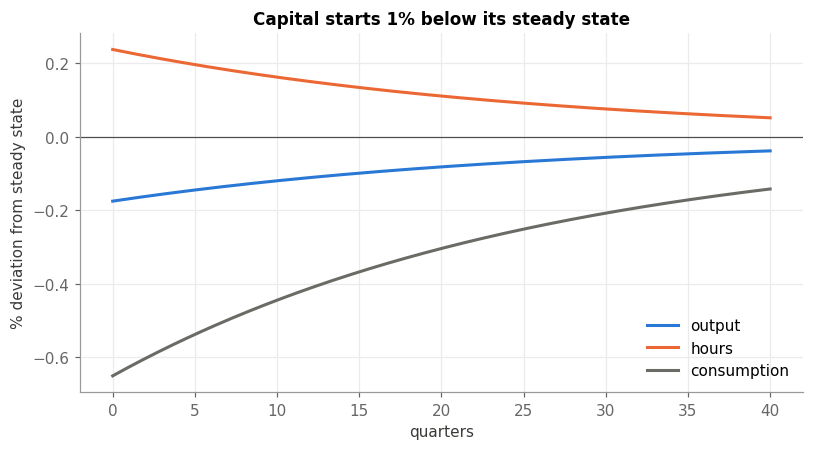

In [13]:
gap = rbc.irf(p, k0=-0.01, T=10, n=401)
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for var, col, lab in [("Y", COLORS["gdp"], "output"), ("L", COLORS["series"], "hours"),
                      ("C", COLORS["trend"], "consumption")]:
    ax.plot(4 * gap.index, gap[var], color=col, lw=2, label=lab)
ax.axhline(0, color="0.3", lw=0.8)
ax.set_xlabel("quarters")
ax.set_ylabel("% deviation from steady state")
ax.set_title("Capital starts 1% below its steady state")
ax.legend(loc="lower right")
plt.tight_layout()

Output and consumption are expected to rise, hours are expected to fall.

We can also compute the predictable movements of Section 6 in our model. As in Rotemberg and Woodford, technology is a random walk. In continuous time the forecast of the state $X_t = (\hat k_t, \hat z_t)'$ at horizon $h$ follows from (STATE): the Brownian increments have mean zero, so $\mathbb{E}_t X_{t+h} = e^{Fh}X_t$. For any variable $v_t = c_v' X_t$ (output, consumption, hours, ...), the predictable change over the next $h$ years is

$$
\Delta\hat v^h_t \equiv \mathbb{E}_t v_{t+h} - v_t = c_v'\left(e^{Fh} - I\right) X_t . \tag{PRED}
$$

With random-walk technology, $\hat z_t$ is not expected to change, and the matrix $e^{Fh} - I$ has rank one: all predictable movements are proportional to the gap between capital and its steady state. The regression coefficients of predictable changes on each other are therefore ratios of the impulse responses in the figure: for example, the consumption coefficient equals the change in consumption over the next $k$ quarters divided by the change in output.

In [14]:
H = 12                                                 # horizon: 12 quarters
rwz = rbc.shock_process(theta_z=0.0)                   # random-walk technology only
F, SX, C = rbc.state_space(p, rwz)
Ad, _ = rbc.discretize(F, SX, 0.25)                    # E_t X_{t+1 quarter} = Ad X_t,  Ad = e^{F/4}
_, X = rbc.simulate(p, rwz, [sigma_z], N_LONG, seed=5, states=True)
X = X[:, 0, :]

lo = rbc.loadings(p)[["Y", "C", "L"]].values / 100     # (k, lam, z, g) -> log deviations of Y, C, L
v = X @ C.T @ lo                                       # simulated log Y, C, L
pred = X @ (np.linalg.matrix_power(Ad, H) - np.eye(len(Ad))).T @ C.T @ lo   # (PRED)
total = v[H:] - v[:-H]


def coef(x, y):                                        # OLS slope of x on y
    return np.cov(x, y)[0, 1] / np.var(y, ddof=1)

d = gap.loc[H / 4] - gap.iloc[0]                       # changes over 12 quarters in the figure
pd.DataFrame({
    "Data (RW 1996)": ["0.72", "0.2 to 0.5", "1"],
    "Model (RW 1996)": ["0.11", "2.5", "-1"],
    "Our model": [f"{np.var(pred[:, 0]) / np.var(total[:, 0]):.3f}",
                  f"{coef(pred[:, 1], pred[:, 0]):.2f}  (figure: {d['C'] / d['Y']:.2f})",
                  f"{coef(pred[:, 2], pred[:, 0]):.2f}  (figure: {d['L'] / d['Y']:.2f})"],
}, index=["predictable / total variance of 12-quarter output change",
          "coefficient of predictable consumption change on output change",
          "coefficient of predictable hours change on output change"])

,Data (RW 1996),Model (RW 1996),Our model
predictable / total variance of 12-quarter output change,0.72,0.11,0.006
coefficient of predictable consumption change on output change,0.2 to 0.5,2.5,3.72 (figure: 3.72)
coefficient of predictable hours change on output change,1,-1,-1.36 (figure: -1.36)


The first row divides predictable by total variance (for Rotemberg and Woodford: $0.0322/0.0445$ and $0.0023/0.0212$). In our model, with random-walk technology, almost none of the variation in output over the next three years is predictable. Consumption is predicted to move several times as much as output, and hours to move in the opposite direction, while in the data consumption, hours and output are all predicted to move together.

Why does the model fail? Rotemberg and Woodford suggest that the model is not rich enough: it misses some margins (e.g., variable factor utilization), and we need more than one shock.

## 7. Try it yourself

1. **How impressive is the fit of output?** The Solow residual in the data is $\hat z_t = \hat y_t - \alpha\hat k_t - (1-\alpha)\hat l_t$, and in the model $\hat y_t = \hat z_t + \alpha\hat k_t + (1-\alpha)\hat l_t$. Show that when we feed the measured Solow residual into the model, the gap between output in the data and in the model is $(1-\alpha)$ times the gap in hours plus $\alpha$ times the gap in capital. Use this to explain why the fit of output in Section 1 is much better than the fit of hours. What does it imply about the case for technology shocks as the driver of business cycles?
2. **Two sources of amplification.** In Section 2 the RBC model amplifies a technology shock more than the simple model on impact but converges faster. Explain both results using the labor market and the household's saving decision. Which parameter would you change to make propagation through capital stronger, and why might that come at the cost of a worse fit elsewhere?
3. **Wages and productivity.** In the model the real wage and output per hour have identical cyclical properties. Why? What features would you add to the model to break the link, and which of them would also help with the low volatility of hours?
4. **Volatility vs. persistence.** Lower the persistence of technology (e.g., $\rho_z = 0.7$) and recalibrate $\sigma_z$ to match the volatility of TFP. Before running the code, predict how the volatility and persistence of output, and the relative volatility of investment and consumption, will change. Relate your answer to the permanent income logic of Lecture 3 and to Rotemberg and Woodford's AR(1) example.
5. **Good news is bad news for hours?** Rotemberg and Woodford find that hours are predicted to fall when output is predicted to rise. Use the labor market diagram of Lecture 3 to explain why this is true in the model whenever capital is below its steady state. What would have to be true about labor demand or labor supply for hours and output to be predicted to move together?
6. **What should we expect from a model?** A critic argues: "With enough shocks and persistent enough forcing processes, any model can match second moments, so matching moments says little." Using the results of Sections 4–6, discuss which moments are informative about the model's internal mechanisms and which mostly reflect the assumed shock processes.

## Summary

- Fed with the measured Solow residual, the calibrated RBC model tracks HP-filtered output, consumption, and investment closely, but not hours ([King and Rebelo, 1999](https://doi.org/10.1016/S1574-0048%2899%2910022-3)).
- We evaluate business cycle models on volatility, correlations, amplification, and propagation. Ideally the model, not the forcing process, generates the volatility and persistence of the data.
- Calibrated to the volatility of the Solow residual, the RBC model with technology shocks generates most of the volatility of output and the ranking $\sigma_I > \sigma_Y > \sigma_C$ ([Cooley and Prescott, 1995](https://doi.org/10.1515/9780691218052-005)).
- It fails on several dimensions: hours are too smooth, wages too procyclical, the real interest rate is too smooth, and everything is too highly correlated with output. Adding government spending shocks trades a better fit for wages against a worse fit for consumption.
- Technology shocks measured by the Solow residual are controversial: technological regress is hard to interpret, and measured TFP responds to demand and monetary shocks.
- The model has weak internal propagation. Output growth is about as autocorrelated as TFP growth ([Cogley and Nason, 1995](https://ideas.repec.org/a/aea/aecrev/v85y1995i3p492-511.html)), and predictable movements are small and have the wrong comovement ([Rotemberg and Woodford, 1996](https://ideas.repec.org/a/aea/aecrev/v86y1996i1p71-89.html)).